# Tarea 28 · Interpretación de los coeficientes del modelo

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/main/notebooks/trabajo/28_interpretacion_coeficientes.ipynb)

**TPI · Introducción al Análisis de Datos · UTN FRA · División 343**
**Integrantes:** Matías, Julián y Emmanuel. **Responsable de esta tarea:** Emmanuel.

Respondemos una pregunta de negocio: **¿qué características de un cliente empujan hacia la baja y cuáles hacia la permanencia?**, usando el modelo de Regresión Logística de la tarea 26. Todo se calcula con los datos de **entrenamiento**; el conjunto de test ya se usó en la tarea 27 y no se vuelve a tocar.

**Conceptos de esta tarea**

- **Coeficiente:** el peso que el modelo le da a una variable. Positivo = la variable aumenta la probabilidad de baja; negativo = la reduce.
- **Odds ratio (`exp(coeficiente)`):** el mismo dato expresado como multiplicador de las chances de baja. Mayor que 1 aumenta las chances; menor que 1 las reduce.
- **"Con lo demás igual":** el coeficiente mide el efecto de una variable manteniendo fijas todas las otras. Es una asociación observada en los datos, **no una prueba de causa y efecto**.
- **Colinealidad:** cuando dos variables miden casi lo mismo, el modelo reparte el efecto entre ellas y sus coeficientes individuales se vuelven poco confiables.

## Cómo ejecutarlo

- **Local:** instalá las dependencias de `requirements.txt`, abrí el notebook desde el repositorio y ejecutá todas las celdas.
- **Colab:** abrí el botón y elegí **Entorno de ejecución → Ejecutar todo**. Los datos se leen desde `main` de GitHub. La imagen queda en `reports/figures/` dentro del panel **Archivos**.

**Nota de alcance.** Complemento conservado porque ya estaba desarrollado: la consigna del recuperatorio no pide clasificación (ver la nota de la tarea 26).


## 1. Estilo común del TPI

Celda definida en la tarea 16 (paleta, tamaños y la función `guardar_figura`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

if EN_COLAB:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / 'PLAN_TAREAS.md').is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')

TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')

Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


## 2. Carga de datos y reconstrucción del modelo

Leemos los datos de entrenamiento y los coeficientes de la tarea 26. Reentrenamos el modelo con la misma configuración (`max_iter=1000`, `random_state=42`) y comprobamos que coincide con los coeficientes guardados.

In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTAS = {
    'x': Path('data/processed/X_train.csv'),
    'y': Path('data/processed/y_train.csv'),
    'coef': Path('data/processed/26_coeficientes_logistica.csv'),
}

def fuente(ruta):
    if EN_COLAB:
        return f'https://raw.githubusercontent.com/{GITHUB_REPO}/{GITHUB_REF}/{ruta.as_posix()}'
    return RAIZ / ruta

X_train = pd.read_csv(fuente(RUTAS['x']), index_col='fila_origen')
y_train = pd.read_csv(fuente(RUTAS['y']), index_col='fila_origen')['Churn']
coef_guardados = pd.read_csv(fuente(RUTAS['coef'])).set_index('variable')

modelo = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)

assert X_train.index.equals(y_train.index)
assert np.allclose(coef_guardados.loc[X_train.columns, 'coeficiente'].to_numpy(), modelo.coef_[0]), \
    'El modelo reentrenado no coincide con la tarea 26.'

print(f'Clientes de entrenamiento: {len(X_train):,} · Variables: {X_train.shape[1]}')
print('El modelo reentrenado coincide con los coeficientes de la tarea 26.')
print(f'Probabilidad media de baja predicha (base): {modelo.predict_proba(X_train)[:, 1].mean():.1%}')

Clientes de entrenamiento: 5,634 · Variables: 46
El modelo reentrenado coincide con los coeficientes de la tarea 26.
Probabilidad media de baja predicha (base): 26.5%


## 3. Primera lectura: los coeficientes de mayor peso

Mostramos los 10 coeficientes más grandes en valor absoluto. Las variables numéricas están estandarizadas, así que su coeficiente se lee "por cada desvío estándar de aumento".

In [3]:
coeficientes = coef_guardados.copy()
coeficientes['coeficiente'] = coeficientes['coeficiente'].round(3)
coeficientes['odds_ratio'] = coeficientes['odds_ratio'].round(3)
coeficientes.head(10)

,coeficiente,odds_ratio
variable,,
numericas__tenure,-1.243,0.289
contrato__Contract,-0.689,0.502
nominal__InternetService_Fiber optic,0.667,1.948
nominal__InternetService_DSL,-0.616,0.540
numericas__MonthlyCharges,-0.586,0.557
nominal__PaperlessBilling_No,-0.294,0.745
nominal__OnlineBackup_No internet service,-0.266,0.766
nominal__OnlineSecurity_No internet service,-0.266,0.766
nominal__InternetService_No,-0.266,0.766


## 4. Antes de interpretar: dos advertencias

Si leyéramos esta tabla al pie de la letra, sacaríamos conclusiones equivocadas. Hay dos problemas.

### 4.1 Columnas repetidas

Varias filas de la tabla tienen **exactamente el mismo coeficiente (−0,266)**. Mostramos cuáles son.

In [4]:
repetidas = coef_guardados['coeficiente'].round(3).value_counts()
valor_repetido = repetidas.index[0]
columnas_repetidas = coef_guardados.index[coef_guardados['coeficiente'].round(3) == valor_repetido].tolist()
print(f'Columnas con coeficiente {valor_repetido}: {len(columnas_repetidas)}')
for columna in columnas_repetidas:
    print(' -', columna)
print()
print('¿Son la misma información?', X_train[columnas_repetidas].nunique().eq(2).all() and
      X_train[columnas_repetidas].T.drop_duplicates().shape[0] == 1)

Columnas con coeficiente -0.266: 7
 - nominal__OnlineBackup_No internet service
 - nominal__OnlineSecurity_No internet service
 - nominal__InternetService_No
 - nominal__TechSupport_No internet service
 - nominal__StreamingMovies_No internet service
 - nominal__DeviceProtection_No internet service
 - nominal__StreamingTV_No internet service



¿Son la misma información? True


Las siete columnas son **la misma información** repetida: "el cliente no tiene internet" (`InternetService = No`) aparece una vez por cada servicio asociado (seguridad, backup, protección, soporte, TV, películas). El modelo reparte el efecto entre las siete. Por eso **ninguna se debe leer por separado**: el efecto real de "no tener internet" es la **suma** de las siete.

### 4.2 Variables numéricas muy relacionadas

`TotalCharges`, `ingreso_estimado` (= `MonthlyCharges × tenure`) y `tenure` están muy relacionadas. El **VIF** mide cuánto se puede reconstruir una variable a partir de las demás: un valor mayor que 10 es una señal de alerta, e infinito significa que es una combinación exacta de las otras.

In [5]:
numericas = [c for c in X_train.columns if c.startswith('numericas__')]
filas = []
for columna in numericas:
    otras = [c for c in numericas if c != columna]
    r2 = LinearRegression().fit(X_train[otras], X_train[columna]).score(X_train[otras], X_train[columna])
    filas.append({'variable': columna.replace('numericas__', ''), 'R2': round(r2, 4),
                  'VIF': 'infinito' if r2 > 0.99999 else round(1 / (1 - r2), 1)})
display(pd.DataFrame(filas).set_index('variable'))

print('Correlación entre variables numéricas (entrenamiento):')
X_train[numericas].rename(columns=lambda c: c.replace('numericas__', '')).corr().round(2)

,R2,VIF
variable,,
tenure,0.8325,6.0
MonthlyCharges,0.6923,3.3
TotalCharges,1.0000,infinito
ingreso_estimado,1.0000,infinito
diferencia_facturacion,1.0000,infinito


Correlación entre variables numéricas (entrenamiento):


,tenure,MonthlyCharges,TotalCharges,ingreso_estimado,diferencia_facturacion
tenure,1.00,0.26,0.83,0.83,0.01
MonthlyCharges,0.26,1.00,0.65,0.65,-0.00
TotalCharges,0.83,0.65,1.00,1.00,0.04
ingreso_estimado,0.83,0.65,1.00,1.00,0.01
diferencia_facturacion,0.01,-0.00,0.04,0.01,1.00


`TotalCharges` e `ingreso_estimado` tienen correlación 1,00 y `diferencia_facturacion` es exactamente su resta, de modo que las tres son una combinación exacta entre sí (VIF infinito). `tenure` y `MonthlyCharges` también quedan relacionadas con ellas (VIF de 6,0 y 3,3). **Consecuencia:** los coeficientes de las variables de facturación no son confiables de forma individual.

## 5. Comprobación de robustez

Probamos qué pasa si quitamos las dos columnas calculadas (`ingreso_estimado` y `diferencia_facturacion`) y reentrenamos. Si una conclusión es sólida, no debería cambiar. Todo se hace con datos de entrenamiento.

In [6]:
sin_calculadas = X_train.drop(columns=['numericas__ingreso_estimado', 'numericas__diferencia_facturacion'])
modelo_reducido = LogisticRegression(max_iter=1000, random_state=42).fit(sin_calculadas, y_train)
coef_reducido = pd.Series(modelo_reducido.coef_[0], index=sin_calculadas.columns)
coef_completo = pd.Series(modelo.coef_[0], index=X_train.columns)

variables_clave = [
    'numericas__tenure', 'contrato__Contract', 'nominal__InternetService_Fiber optic',
    'nominal__InternetService_DSL', 'nominal__PaperlessBilling_Yes',
    'numericas__MonthlyCharges', 'numericas__TotalCharges',
]
robustez = pd.DataFrame({
    'con todas las variables': coef_completo[variables_clave],
    'sin columnas calculadas': coef_reducido[variables_clave],
}).round(3)
display(robustez)
print(f'Accuracy en entrenamiento: {modelo.score(X_train, y_train):.1%} (completo) · '
      f'{modelo_reducido.score(sin_calculadas, y_train):.1%} (sin columnas calculadas)')

,con todas las variables,sin columnas calculadas
numericas__tenure,-1.243,-1.250
contrato__Contract,-0.689,-0.693
nominal__InternetService_Fiber optic,0.667,0.672
nominal__InternetService_DSL,-0.616,-0.620
nominal__PaperlessBilling_Yes,0.078,0.078
numericas__MonthlyCharges,-0.586,-0.598
numericas__TotalCharges,0.259,0.528


Accuracy en entrenamiento: 80.6% (completo) · 80.6% (sin columnas calculadas)


**Lectura:**

- `tenure`, `Contract`, fibra óptica y DSL **casi no cambian** al quitar las columnas calculadas. Son conclusiones **sólidas**.
- `TotalCharges` **sí cambia mucho** (de 0,26 a 0,53): su coeficiente depende de qué otras variables acompañen al modelo. **No se debe interpretar**.
- `MonthlyCharges` mantiene signo negativo en ambos casos aunque quienes se van pagan más (gráficos de la tarea 17). Es un efecto de "con lo demás igual": una vez que el modelo ya sabe qué servicio tiene el cliente (por ejemplo, fibra óptica, que es cara), el cargo extra no agrega información por sí mismo. El cargo alto se refleja a través del tipo de servicio.
- El rendimiento sobre entrenamiento es prácticamente igual (80,6 %): las columnas calculadas no aportan al modelo.

## 6. Efecto de cada variable en la probabilidad de baja

Los coeficientes y odds ratios son difíciles de comunicar. Una forma más clara: **¿cuánto cambia la probabilidad de baja si todos los clientes pertenecieran a una categoría u otra?** Para cada variable, fijamos esa característica en todos los clientes de entrenamiento, dejando todo lo demás como está, y calculamos la probabilidad media de baja que predice el modelo. Esto resuelve el problema de las columnas repetidas, porque se cambia el conjunto completo de columnas de cada variable a la vez.

Es una simulación del modelo, no un experimento: muestra qué asocia el modelo con cada característica, no qué pasaría si la empresa cambiara a los clientes de categoría.

In [7]:
def probabilidad_media(cambios):
    escenario = X_train.copy()
    for columna, valor in cambios.items():
        escenario[columna] = valor
    return modelo.predict_proba(escenario)[:, 1].mean()

def fijar_categoria(prefijo, categoria):
    cambios = {c: 0.0 for c in X_train.columns if c.startswith(prefijo)}
    cambios[prefijo + categoria] = 1.0
    return cambios

base = modelo.predict_proba(X_train)[:, 1].mean()
desvio = 1.0  # tenure ya está estandarizado: 1 unidad = 1 desvío estándar (≈ 25 meses)

escenarios = [
    ('Antigüedad', '1 desvío menos (cliente más nuevo)', {'numericas__tenure': X_train['numericas__tenure'] - desvio}),
    ('Antigüedad', 'Antigüedad actual', {}),
    ('Antigüedad', '1 desvío más (cliente más antiguo)', {'numericas__tenure': X_train['numericas__tenure'] + desvio}),
    ('Contrato', 'Mensual', {'contrato__Contract': 0.0}),
    ('Contrato', 'Un año', {'contrato__Contract': 1.0}),
    ('Contrato', 'Dos años', {'contrato__Contract': 2.0}),
    ('Internet', 'DSL', fijar_categoria('nominal__InternetService_', 'DSL')),
    ('Internet', 'Fibra óptica', fijar_categoria('nominal__InternetService_', 'Fiber optic')),
    ('Pago', 'Cheque electrónico', fijar_categoria('nominal__PaymentMethod_', 'Electronic check')),
    ('Pago', 'Cheque por correo', fijar_categoria('nominal__PaymentMethod_', 'Mailed check')),
    ('Pago', 'Transferencia automática', fijar_categoria('nominal__PaymentMethod_', 'Bank transfer (automatic)')),
    ('Pago', 'Tarjeta automática', fijar_categoria('nominal__PaymentMethod_', 'Credit card (automatic)')),
    ('Factura electrónica', 'Sí', fijar_categoria('nominal__PaperlessBilling_', 'Yes')),
    ('Factura electrónica', 'No', fijar_categoria('nominal__PaperlessBilling_', 'No')),
]
efectos = pd.DataFrame(
    [{'variable': v, 'escenario': e, 'prob_baja': probabilidad_media(c)} for v, e, c in escenarios]
)
efectos['diferencia_vs_base_pp'] = (efectos['prob_baja'] - base) * 100

print(f'Probabilidad media de baja con los clientes tal como están: {base:.1%}')
mostrar = efectos.copy()
mostrar['prob_baja'] = (mostrar['prob_baja'] * 100).round(1).astype(str) + ' %'
mostrar['diferencia_vs_base_pp'] = mostrar['diferencia_vs_base_pp'].round(1)
mostrar.set_index(['variable', 'escenario'])

Probabilidad media de baja con los clientes tal como están: 26.5%


prob_baja  \
variable            escenario                                      
Antigüedad          1 desvío menos (cliente más nuevo)    44.7 %   
                    Antigüedad actual                     26.5 %   
                    1 desvío más (cliente más antiguo)    12.4 %   
Contrato            Mensual                               29.8 %   
                    Un año                                19.9 %   
                    Dos años                              12.4 %   
Internet            DSL                                   16.7 %   
                    Fibra óptica                          34.4 %   
Pago                Cheque electrónico                    29.3 %   
                    Cheque por correo                     25.0 %   
                    Transferencia automática              24.0 %   
                    Tarjeta automática                    23.5 %   
Factura electrónica Sí                                    28.2 %   
                    No                                    23.1 %   

                                                        diferencia_vs_base_pp  
variable            escenario                                                  
Antigüedad          1 desvío menos (cliente más nuevo)                   18.2  
                    Antigüedad actual                                     0.0  
                    1 desvío más (cliente más antiguo)                  -14.1  
Contrato            Mensual                                               3.2  
                    Un año                                               -6.6  
                    Dos años                                            -14.2  
Internet            DSL                                                  -9.9  
                    Fibra óptica                                          7.9  
Pago                Cheque electrónico                                    2.8  
                    Cheque por correo                                    -1.6  
                    Transferencia automática                             -2.6  
                    Tarjeta automática                                   -3.0  
Factura electrónica Sí                                                    1.7  
                    No                                                   -3.4

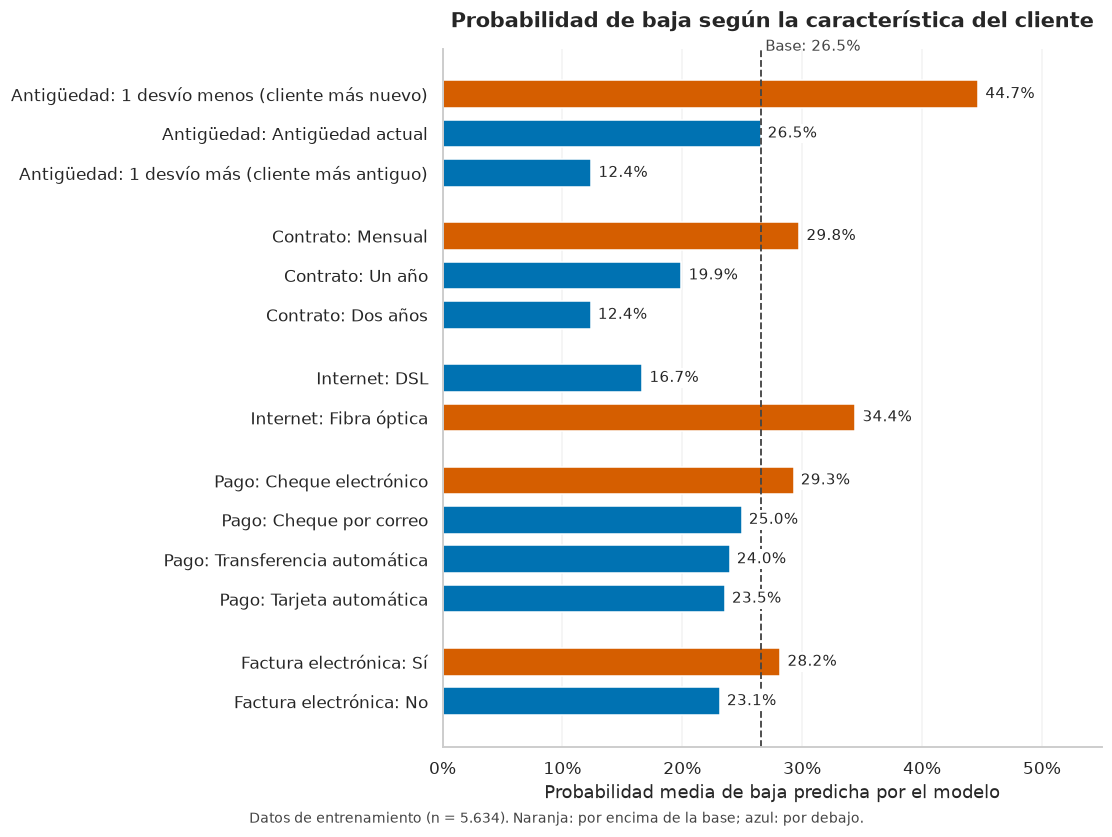

Figura exportada: reports/figures/28_efecto_variables.png


In [8]:
fig, ax = plt.subplots(figsize=(10, 7.5), layout='constrained')

posiciones, etiquetas, y_actual = [], [], 0
for variable, grupo in efectos.groupby('variable', sort=False):
    for _, fila in grupo.iterrows():
        color = COLORES_CHURN['Yes'] if fila['prob_baja'] > base else COLORES_CHURN['No']
        ax.barh(y_actual, fila['prob_baja'], color=color, height=0.7)
        ax.text(fila['prob_baja'] + 0.006, y_actual, f"{fila['prob_baja']:.1%}", va='center', fontsize=10,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5}, zorder=5)
        posiciones.append(y_actual)
        etiquetas.append(f"{variable}: {fila['escenario']}")
        y_actual += 1
    y_actual += 0.6  # espacio entre variables

ax.axvline(base, color='#444444', linestyle='--', linewidth=1.2, zorder=1)
ax.text(base + 0.004, -1.1, f'Base: {base:.1%}', fontsize=10, color='#444444')
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, 0.55)
ax.set_xlabel('Probabilidad media de baja predicha por el modelo')
ax.set_title('Probabilidad de baja según la característica del cliente', pad=14)
ax.yaxis.grid(False)
fig.supxlabel('Datos de entrenamiento (n = 5.634). Naranja: por encima de la base; azul: por debajo.',
              fontsize=9, color='#444444')

ruta = guardar_figura(fig, '28_efecto_variables')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta.relative_to(RAIZ).as_posix()}')

## 7. Variables destacadas y su lectura de negocio

Estas son las cinco variables con efecto más claro. Las tres primeras son **sólidas** (no cambian al quitar columnas calculadas); las dos últimas son efectos **más modestos**.

1. **Antigüedad (`tenure`): el factor más fuerte.** Con un desvío estándar (≈ 25 meses) menos de antigüedad, la probabilidad de baja sube a 44,7 %; con uno más, baja a 12,4 %. *Lectura de negocio:* el riesgo se concentra en los primeros meses. Es consistente con los histogramas de la tarea 17. Conviene reforzar la retención en clientes nuevos (bienvenida, seguimiento, ofertas tempranas).
2. **Tipo de contrato: la permanencia se premia con estabilidad.** Si todos tuvieran contrato mensual, la probabilidad sería 29,8 %; con contrato de un año, 19,9 %, y de dos años, 12,4 %. *Lectura de negocio:* los contratos largos van asociados a menos bajas. Una acción posible es ofrecer incentivos para migrar clientes del plan mensual a uno anual.
3. **Internet de fibra óptica: el servicio con más riesgo.** Con DSL la probabilidad es 16,7 % y con fibra, 34,4 %: casi 18 puntos porcentuales de diferencia. *Lectura de negocio:* la fibra, que es el servicio más caro, concentra bajas. Convendría revisar su relación calidad-precio y si el cliente percibe el valor. Esto coincide con el hallazgo 3 del análisis exploratorio.
4. **Cheque electrónico como método de pago.** Con cheque electrónico la probabilidad es 29,3 %, frente a 23,5 % con tarjeta automática y 24,0 % con transferencia automática (unos 6 puntos más). *Lectura de negocio:* los pagos automáticos se asocian a menos bajas. Podría incentivarse el débito automático. El efecto es más modesto que los anteriores.
5. **Factura electrónica (`PaperlessBilling`).** Con factura electrónica la probabilidad es 28,2 % y sin ella, 23,1 % (5 puntos más). *Lectura de negocio:* un efecto moderado; sirve como señal de riesgo complementaria, no como causa.

**Variables que no se deben interpretar individualmente:** `MonthlyCharges`, `TotalCharges`, `ingreso_estimado` y `diferencia_facturacion`, por colinealidad (sección 4.2), y los coeficientes de cada servicio "No internet service", por columnas repetidas (sección 4.1).

## 8. Límites de esta interpretación

- **Asociación, no causalidad.** El modelo describe qué características acompañan a las bajas. No demuestra que cambiar el contrato de un cliente evite que se vaya.
- **Datos de entrenamiento.** Los porcentajes salen de simular el modelo sobre los clientes de entrenamiento; no son una medición sobre clientes nuevos.
- **El modelo es imperfecto.** En test detecta cerca del 56 % de las bajas (tarea 27). Las conclusiones valen como pistas de dónde mirar, no como regla exacta.

## 9. Resultado de la tarea

Se interpretó el modelo con cuidado: se detectaron las columnas repetidas y la colinealidad que hacen engañosa la lectura directa de los coeficientes, se verificó la robustez quitando las columnas calculadas y se tradujo el efecto de cada variable a probabilidad de baja. Las variables más relevantes son la **antigüedad**, el **contrato** y la **fibra óptica**, seguidas por el **método de pago** y la **factura electrónica**. La figura `reports/figures/28_efecto_variables.png` queda disponible para el informe.